In [1]:
# ---- Setup: Drive + code + wandb (run this first, every session) ----
REPO_URL = "https://github.com/ammara-asif/fyp.git"   # <-- EDIT ONCE
BRANCH = "nested-b-d"   # the branch with the code this notebook needs (set back to "main" after merging)

import os, subprocess, sys
from google.colab import drive, userdata

# Drive must be mounted from the notebook kernel (never from a !python subprocess).
drive.mount("/content/drive")

# Code: fresh clone each session (Colab disk is wiped on reset), pull if it already exists.
# For a private repo, add a Colab secret GITHUB_TOKEN (a fine-grained read-only token).
CODE = "/content/fyp"
url = REPO_URL
try:
    tok = userdata.get("GITHUB_TOKEN")
    url = REPO_URL.replace("https://", f"https://{tok}@")
except Exception:
    pass
if not os.path.isdir(CODE):
    subprocess.run(["git", "clone", "-q", url, CODE], check=True)
# fetch + checkout + pull, so a clone left on another branch earlier in the session switches over
subprocess.run(["git", "-C", CODE, "fetch", "-q", "origin"], check=True)
subprocess.run(["git", "-C", CODE, "checkout", "-q", BRANCH], check=True)
subprocess.run(["git", "-C", CODE, "pull", "-q", "origin", BRANCH], check=True)
print(BRANCH, subprocess.check_output(["git", "-C", CODE, "log", "-1", "--oneline"]).decode())

# Dependencies (torch/torchvision come preinstalled with Colab's CUDA build; don't reinstall them).
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"{CODE}/requirements.txt"], check=True)

# wandb: key comes from the Colab secret WANDB_API_KEY (key icon in the left sidebar). Never hardcode it.
import wandb
wandb.login(key=userdata.get("WANDB_API_KEY"))

sys.path.insert(0, f"{CODE}/src")
# Python caches imported modules for the whole kernel session, so after a git pull
# a plain `import` would silently keep running the OLD code. Drop the cached copies.
_MINE = {"fyp_infra", "stage1_runner", "stage1_analysis", "stage1_drift_diagnostic",
         "stage1_structural", "nested_builder"}
for _m in list(sys.modules):
    if _m in _MINE or _m == "src" or _m.startswith("src."):   # src.* = the team's nested code
        sys.modules.pop(_m, None)
import torch
from fyp_infra import setup_paths, run_sweep, run_id, load_result
import stage1_runner as sr
paths = setup_paths()   # -> /content/drive/MyDrive/fyp_nested_cl/{data,results,logs}
print(paths)
# Hard stop for training: a CPU run is ~12x slower and its timings are useless for budgeting.
REQUIRE_GPU = False   # analysis only: CPU runtime is fine
if REQUIRE_GPU:
    assert torch.cuda.is_available(), "No GPU! Runtime -> Change runtime type -> T4 GPU, then restart."
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU runtime)")

Mounted at /content/drive
nested-b-d fed9369 nested variants



/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: ammara-asif125 (kashaf-saleem09-institute-of-business-administration) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


{'root': '/content/drive/MyDrive/fyp_nested_cl', 'data': '/content/drive/MyDrive/fyp_nested_cl/data', 'results': '/content/drive/MyDrive/fyp_nested_cl/results', 'logs': '/content/drive/MyDrive/fyp_nested_cl/logs', 'checkpoints': '/content/drive/MyDrive/fyp_nested_cl/checkpoints'}
GPU: Tesla T4


In [6]:
import stage1_analysis as sa
import stage1_drift_diagnostic as dd
STAGES = ["stage1_control", "stage1_nested_control"]   # old control arms + Flat/B/D via the nested path
TRAIN_RUNS = sa.list_runs(paths, stage=STAGES)
for r in TRAIN_RUNS:
    c = r["config"]; print(r["run_id"], sr.arm_label(c), "lr", c["lr"], "seed", c["seed"])
DCFGS = dd.diagnostic_configs(TRAIN_RUNS)

07a97dd12ec3 flat_nl lr 0.1 seed 0
1803d732791d llrd_fast_deep lr 0.6 seed 1
32e5df8b8886 flat lr 0.3 seed 2
48523f3dfeea nested_b lr 0.6 seed 1
4b2bd0082f5c flat lr 0.1 seed 0
78e133183087 flat_nl lr 0.1 seed 1
7b3073002436 flat lr 0.3 seed 0
892486433e6d flat lr 0.1 seed 1
9d5d9fcc4194 llrd_fast_deep lr 0.6 seed 0
b09e3cc29bda flat_nl lr 0.1 seed 2
b2316f2cb5f4 nested_d_lam0.01 lr 0.7 seed 0
b409e8563692 llrd_fast_deep lr 0.6 seed 2
badf7f571542 nested_b lr 0.6 seed 2
bf6b7bf5e853 llrd_slow_deep lr 0.5 seed 2
bf7c7b91a468 llrd_slow_deep lr 0.5 seed 1
c4b3004f3b61 nested_d_lam0.01 lr 0.7 seed 2
e3be0b8051fd nested_d_lam0.01 lr 0.7 seed 1
e3f9264b4607 flat lr 0.1 seed 2
ea0983312db5 nested_b lr 0.6 seed 0
f686172d0a03 flat lr 0.3 seed 1
f7af3b7e79aa llrd_slow_deep lr 0.5 seed 0


In [7]:
out = run_sweep(DCFGS, dd.diagnose_run, paths)

[1/21] 5165d0c6b6bd running
  task 1/19: deepest-level drift 0.0 pts
  task 2/19: deepest-level drift 4.0 pts
  task 3/19: deepest-level drift 7.8 pts
  task 4/19: deepest-level drift 7.8 pts
  task 5/19: deepest-level drift 10.0 pts
  task 6/19: deepest-level drift 15.6 pts
  task 7/19: deepest-level drift 8.2 pts
  task 8/19: deepest-level drift 9.6 pts
  task 9/19: deepest-level drift 8.4 pts
  task 10/19: deepest-level drift 8.2 pts
  task 11/19: deepest-level drift 12.2 pts
  task 12/19: deepest-level drift 9.4 pts
  task 13/19: deepest-level drift 13.2 pts
  task 14/19: deepest-level drift 13.6 pts
  task 15/19: deepest-level drift 10.0 pts
  task 16/19: deepest-level drift 7.6 pts
  task 17/19: deepest-level drift 9.4 pts
  task 18/19: deepest-level drift 7.8 pts
  task 19/19: deepest-level drift 5.2 pts
[2/21] 31f42fe7a109 already finished, skipping
[3/21] a228a311bfa6 already finished, skipping
[4/21] 876ad5822c1f running


/content/fyp/src/stage1_drift_diagnostic.py:155: RuntimeWarning: Mean of empty slice
  mean = {c: np.nanmean(acc[c], axis=1) for c in CONDITIONS}


  task 1/19: deepest-level drift 8.0 pts
  task 2/19: deepest-level drift 9.0 pts
  task 3/19: deepest-level drift 10.4 pts
  task 4/19: deepest-level drift 6.6 pts
  task 5/19: deepest-level drift 17.4 pts
  task 6/19: deepest-level drift 11.4 pts
  task 7/19: deepest-level drift 7.2 pts
  task 8/19: deepest-level drift 7.4 pts
  task 9/19: deepest-level drift 13.8 pts
  task 10/19: deepest-level drift 17.4 pts
  task 11/19: deepest-level drift 10.6 pts
  task 12/19: deepest-level drift 9.0 pts
  task 13/19: deepest-level drift 14.2 pts
  task 14/19: deepest-level drift 15.4 pts
  task 15/19: deepest-level drift 14.6 pts
  task 16/19: deepest-level drift 13.8 pts
  task 17/19: deepest-level drift 13.0 pts
  task 18/19: deepest-level drift 15.6 pts
  task 19/19: deepest-level drift 9.4 pts
[5/21] 850d15c7deff already finished, skipping
[6/21] e0f5fa60d3d4 running


/content/fyp/src/stage1_drift_diagnostic.py:155: RuntimeWarning: Mean of empty slice
  mean = {c: np.nanmean(acc[c], axis=1) for c in CONDITIONS}


  task 1/19: deepest-level drift 3.4 pts
  task 2/19: deepest-level drift 3.2 pts
  task 3/19: deepest-level drift 8.2 pts
  task 4/19: deepest-level drift 7.0 pts
  task 5/19: deepest-level drift 15.6 pts
  task 6/19: deepest-level drift 9.2 pts
  task 7/19: deepest-level drift 8.4 pts
  task 8/19: deepest-level drift 12.6 pts
  task 9/19: deepest-level drift 12.4 pts
  task 10/19: deepest-level drift 18.6 pts
  task 11/19: deepest-level drift 11.0 pts
  task 12/19: deepest-level drift 7.8 pts
  task 13/19: deepest-level drift 13.0 pts
  task 14/19: deepest-level drift 17.8 pts
  task 15/19: deepest-level drift 13.6 pts
  task 16/19: deepest-level drift 12.4 pts
  task 17/19: deepest-level drift 11.6 pts
  task 18/19: deepest-level drift 13.2 pts
  task 19/19: deepest-level drift 11.4 pts
[7/21] 9678e2a53e22 already finished, skipping
[8/21] 5c234f8afae0 already finished, skipping
[9/21] 0d8619684311 already finished, skipping
[10/21] e95fe1d758f8 running


...

/content/fyp/src/stage1_drift_diagnostic.py:155: RuntimeWarning: Mean of empty slice
  mean = {c: np.nanmean(acc[c], axis=1) for c in CONDITIONS}


  task 1/19: deepest-level drift 5.8 pts
  task 2/19: deepest-level drift 2.4 pts
  task 3/19: deepest-level drift 6.8 pts
  task 4/19: deepest-level drift 8.2 pts
  task 5/19: deepest-level drift 11.0 pts
  task 6/19: deepest-level drift 4.8 pts
  task 7/19: deepest-level drift 6.2 pts
  task 8/19: deepest-level drift 13.8 pts
  task 9/19: deepest-level drift 13.0 pts
  task 10/19: deepest-level drift 16.2 pts
  task 11/19: deepest-level drift 11.2 pts
  task 12/19: deepest-level drift 9.8 pts
  task 13/19: deepest-level drift 10.2 pts
  task 14/19: deepest-level drift 20.4 pts
  task 15/19: deepest-level drift 16.8 pts
  task 16/19: deepest-level drift 14.0 pts
  task 17/19: deepest-level drift 9.4 pts
  task 18/19: deepest-level drift 12.2 pts
  task 19/19: deepest-level drift 6.8 pts
[18/21] f385247f2ccc already finished, skipping
[19/21] ff29693c8cd9 running


/content/fyp/src/stage1_drift_diagnostic.py:155: RuntimeWarning: Mean of empty slice
  mean = {c: np.nanmean(acc[c], axis=1) for c in CONDITIONS}


  task 1/19: deepest-level drift -1.2 pts
  task 2/19: deepest-level drift 5.8 pts
  task 3/19: deepest-level drift 6.4 pts
  task 4/19: deepest-level drift 6.4 pts
  task 5/19: deepest-level drift 9.0 pts
  task 6/19: deepest-level drift 14.0 pts
  task 7/19: deepest-level drift 9.4 pts
  task 8/19: deepest-level drift 7.6 pts
  task 9/19: deepest-level drift 9.0 pts
  task 10/19: deepest-level drift 14.0 pts
  task 11/19: deepest-level drift 12.0 pts
  task 12/19: deepest-level drift 9.4 pts
  task 13/19: deepest-level drift 15.2 pts
  task 14/19: deepest-level drift 11.4 pts
  task 15/19: deepest-level drift 7.8 pts
  task 16/19: deepest-level drift 8.0 pts
  task 17/19: deepest-level drift 8.4 pts
  task 18/19: deepest-level drift 11.6 pts
  task 19/19: deepest-level drift 6.4 pts
[20/21] 0f1d70cbbef4 already finished, skipping
[21/21] e1f4886708d2 already finished, skipping


/content/fyp/src/stage1_drift_diagnostic.py:155: RuntimeWarning: Mean of empty slice
  mean = {c: np.nanmean(acc[c], axis=1) for c in CONDITIONS}


In [8]:
import numpy as np, pandas as pd
PARTS = ["total_drift", "own_drift", "inherited_drift", "interaction", "bn_recovery", "bn_procedure_effect"]
rows = []
for a in DCFGS:
    r = load_result(a, paths)
    if r is None: continue
    m = r["metrics"]; c = m["train_config"]
    for l, name in enumerate(m["level_modules"]):
        rows.append({"arm": sr.arm_label(c), "lr": c["lr"], "seed": c["seed"], "level": name,
                     **{p: m[p][l] for p in PARTS}})
ddf = pd.DataFrame(rows)
summary = ddf.drop(columns="seed").groupby(["arm", "lr", "level"]).agg(["mean", "std"]).round(2)
display(summary)

total_drift       own_drift       inherited_drift  \
                                   mean   std      mean   std            mean   
arm              lr  level                                                      
flat             0.1 layer1        2.03  0.48      2.03  0.48            0.00   
                     layer3        5.78  0.61      4.71  0.55            4.45   
                     layer4        8.35  0.50      0.99  0.35            8.99   
                 0.3 layer1        2.01  0.39      2.01  0.39            0.00   
                     layer3        6.85  0.55      4.66  0.37            3.94   
                     layer4       10.04  0.31      1.01  0.13            9.24   
flat_nl          0.1 layer1        1.06  1.09      1.06  1.09            0.00   
                     layer3        6.27  0.69      4.92  0.65            4.62   
                     layer4        9.41  1.47      1.07  0.18           10.24   
llrd_fast_deep   0.6 layer1        1.27  0.82      1.27  0.82            0.00   
                     layer3        5.79  0.89      4.73  0.17            3.35   
                     layer4        9.51  0.45      1.34  0.29            8.97   
llrd_slow_deep   0.5 layer1        1.28  0.93      1.28  0.93            0.00   
                     layer3        6.98  1.23      5.19  1.26            5.16   
                     layer4       10.02  1.42      0.58  0.14           10.22   
nested_b         0.6 layer1        1.11  0.48      1.11  0.48            0.00   
                     layer3        6.31  0.66      4.92  1.12            3.78   
                     layer4       10.14  1.48      1.61  0.41            9.38   
nested_d_lam0.01 0.7 layer1        1.27  0.78      1.27  0.78            0.00   
                     layer3        5.27  1.44      4.88  1.30            2.79   
                     layer4        9.68  1.18      1.61  0.37            8.76   

                                  interaction       bn_recovery        \
                              std        mean   std        mean   std   
arm              lr  level                                              
flat             0.1 layer1  0.00        0.00  0.00        0.13  0.24   
                     layer3  0.84       -3.38  0.50       -0.27  0.39   
                     layer4  0.80       -1.64  0.37       -0.69  0.69   
                 0.3 layer1  0.00        0.00  0.00        0.21  0.18   
                     layer3  0.94       -1.74  0.95       -0.17  0.44   
                     layer4  0.80       -0.21  0.61       -0.32  0.36   
flat_nl          0.1 layer1  0.00        0.00  0.00       -0.16  0.38   
                     layer3  0.71       -3.27  0.62        0.02  0.54   
                     layer4  1.43       -1.90  0.31       -0.24  0.36   
llrd_fast_deep   0.6 layer1  0.00        0.00  0.00       -0.05  0.15   
                     layer3  0.54       -2.29  0.52       -0.36  0.09   
                     layer4  0.60       -0.80  0.67       -0.15  0.30   
llrd_slow_deep   0.5 layer1  0.00        0.00  0.00       -0.16  0.12   
                     layer3  0.93       -3.38  0.73       -0.29  0.37   
                     layer4  1.70       -0.77  0.44       -0.34  0.67   
nested_b         0.6 layer1  0.00        0.00  0.00       -0.11  0.40   
                     layer3  0.19       -2.39  0.39        0.04  0.17   
                     layer4  1.22       -0.85  0.40       -0.58  0.38   
nested_d_lam0.01 0.7 layer1  0.00        0.00  0.00        0.00  0.22   
                     layer3  0.41       -2.41  0.78       -0.34  0.29   
                     layer4  1.21       -0.69  0.39       -0.85  0.54   

                            bn_procedure_effect        
                                           mean   std  
arm              lr  level                             
flat             0.1 layer1               -0.32  0.42  
                     layer3               -0.35  0.25  
                     layer4               -0.81  0

In [9]:
diffs = []
for a in DCFGS:
    r = load_result(a, paths)
    ra = load_result({"analysis": sa.ANALYSIS_VERSION, "train_run_id": a["train_run_id"]}, paths)
    if r is None or ra is None: continue
    diffs += [abs(x - y) for x, y in zip(r["metrics"]["total_drift"], ra["metrics"]["probe_forgetting"])]
print(f"max |total_drift - probe_forgetting| = {max(diffs):.3f} points over {len(diffs)} values" if diffs
      else "no stage1_analysis results found to compare against")

max |total_drift - probe_forgetting| = 0.053 points over 63 values


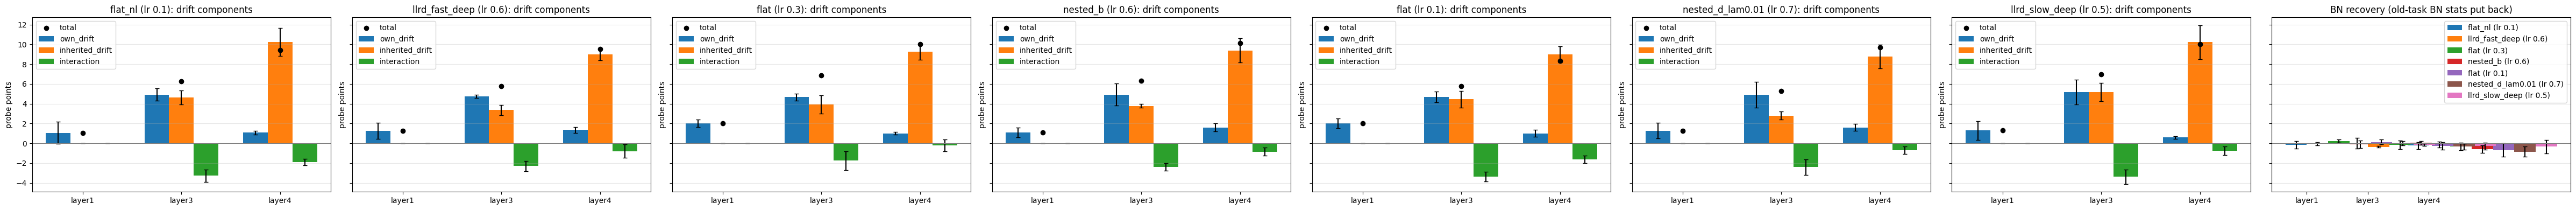

In [10]:
import matplotlib.pyplot as plt
levels = list(dict.fromkeys(ddf["level"]))
arms = list(dict.fromkeys(zip(ddf["arm"], ddf["lr"])))
comps = ["own_drift", "inherited_drift", "interaction"]
fig, axes = plt.subplots(1, len(arms) + 1, figsize=(6 * (len(arms) + 1), 4), sharey=True)
for ax, (arm, lr) in zip(axes, arms):
    g = ddf[(ddf["arm"] == arm) & (ddf["lr"] == lr)]
    w = 0.25
    for k, comp in enumerate(comps):
        stats = g.groupby("level")[comp].agg(["mean", "std"]).reindex(levels)
        ax.bar(np.arange(len(levels)) + (k - 1) * w, stats["mean"], w, yerr=stats["std"], capsize=3, label=comp)
    tot = g.groupby("level")["total_drift"].mean().reindex(levels)
    ax.scatter(np.arange(len(levels)), tot, color="black", zorder=3, label="total")
    ax.set(title=f"{arm} (lr {lr}): drift components", xticks=range(len(levels)), xticklabels=levels, ylabel="probe points")
    ax.axhline(0, color="grey", lw=.8); ax.legend(); ax.grid(alpha=.3, axis="y")
ax = axes[-1]
for k, (arm, lr) in enumerate(arms):
    g = ddf[(ddf["arm"] == arm) & (ddf["lr"] == lr)]
    stats = g.groupby("level")["bn_recovery"].agg(["mean", "std"]).reindex(levels)
    ax.bar(np.arange(len(levels)) + (k - 0.5) * 0.35, stats["mean"], 0.35, yerr=stats["std"], capsize=3, label=f"{arm} (lr {lr})")
ax.set(title="BN recovery (old-task BN stats put back)", xticks=range(len(levels)), xticklabels=levels)
ax.axhline(0, color="grey", lw=.8); ax.legend(); ax.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()